# MECHA in metafspm, 1: GRANAP's anatomies, MECHA's hydraulics

MECHA's legacy reads one cross section from an XML file and builds its own network. In metafspm, GRANAP's component
writes every section's network into the plant graph, and MECHA's component, `MechaHydraulics`, reads it from there.
Coupling them is assembling a plant model; parametrizing them is giving each plant a scenario, as in Wheat-BRIDGES.

> **Developer tutorial 1** of seven:
> | | notebook | what it covers |
> |---|---|---|
> | 0 | `00_overview.ipynb` | the package's modules, the original MECHA and its reactions branch, how the port is validated, the docs |
> | 1 | `01_granap_mecha.ipynb` | GRANAP's anatomies and MECHA's hydraulics coupled in a plant model; MECHA's inputs by role; scenarios; the barriers |
> | 2 | `02_soil_gradient.ipynb` | the plant problem with a soil drier on one side of a root section |
> | 3 | `03_needle_solutes.ipynb` | a pine needle of three sections, its transpiration, MechaSolutes over a day |
> | 4 | `04_full_plant.ipynb` | a whole seedling in its soil, run to the fixed point |
> | 5 | `05_extend_the_component.ipynb` | add a variable and a process to the component, run and test it |
> | 6 | `06_solute_storage_and_decay.ipynb` | the solutes' storage fractions, their first-order loss and the liquid boundary |
>
> New to MECHA? Start with the user tutorials (`../user/01_first_run.ipynb`): they solve a root section and explain
> its results without the framework's details.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from openalea.metafspm.coupling.composite_wrapper import CompositeModel
from openalea.metafspm.coupling.translator import Translator
from openalea.metafspm.scene.scene import Scene

from openalea.granap.metafspm.architectures import RootAxis
from openalea.granap.metafspm.component import GranapAnatomy, junction_rules
from openalea.mecha import plots
from openalea.mecha.component import MechaHydraulics

## 1. The plant model

Two components on one DataStructure. `GranapAnatomy` writes the sections' networks (tissues, cell areas, wall
lengths, edges); `MechaHydraulics` declares the same variables as its inputs, so they are coupled by name: no
component imports or calls another. `run` is one time step: the anatomies first, then the hydraulics.

In [2]:
class RootHydraulics(CompositeModel):
    initiators = (RootAxis, GranapAnatomy)
    from_scale, nodes, wiring = "SubOrgan", "Compartment", junction_rules

    def __init__(self, data_structure, time_step):
        self.anatomy = GranapAnatomy(data_structure=data_structure, time_step=time_step)
        self.hydraulics = MechaHydraulics(data_structure=data_structure, time_step=time_step)
        self.declare_data_and_couple_components(translator_path=Translator(),
                                                components=(self.anatomy, self.hydraulics))

    def run(self):
        self.anatomy()
        self.hydraulics()


def plants(model, *scenarios):
    """A planting table: one plant per scenario."""
    return pd.DataFrame([dict(plant=f"plant {i}", model=model, x=float(i), y=0., z=0., rotation=0.,
                              scenario={"parameters": parameters}) for i, parameters in enumerate(scenarios)])

What MECHA reads, and from whom: each input names the role of the model providing it. `Anatomy` is GRANAP; the
others are given by other models in a full simulation (a development model for the barriers, a soil model, a
solute model), else they keep their declared defaults.

In [3]:
inputs = pd.DataFrame([(name, f.metadata["by"], f.metadata.get("unit"), f.metadata.get("initialize"))
                       for name, f in MechaHydraulics.__dataclass_fields__.items()
                       if f.metadata.get("variable_type") == "input"],
                      columns=["input", "provided by", "unit", "default"]).set_index("input")
inputs.sort_values("provided by")

,provided by,unit,default
input,,,
kind,Anatomy,,None
anatomy_template,Anatomy,,None
edge_dist,Anatomy,mm,None
edge_length,Anatomy,mm,None
pore_depth,Anatomy,mm,None
pore_width,Anatomy,mm,None
wall_thickness,Anatomy,µm,None
network_path,Anatomy,,None
wall_length,Anatomy,mm,None


## 2. One section

One plant with the default scenario: one root segment, GRANAP's monocot root preset, MECHA's default parameters.
The scene builds the plant and calls the model once: GRANAP's anatomy, then MECHA's conductances and its standard
problem (the section alone, the soil at 0 hPa, the xylem at −5000 hPa), which gives MECHA's radial conductivity kr.

In [4]:
scene = Scene(plants(RootHydraulics, {}))
scene.run()
ds = scene.populations[0].data_structure
mecha = scene.populations[0].instance.hydraulics
segment = int(ds.entity_ids("SubOrgan")[0])
print(f"kr {ds.get('kr')[0]:.3e} cm hPa⁻¹ d⁻¹, uptake {ds.get('standard_uptake')[0]:.3e} cm³ d⁻¹")

kr 1.101e-04 cm hPa⁻¹ d⁻¹, uptake 2.772e-03 cm³ d⁻¹


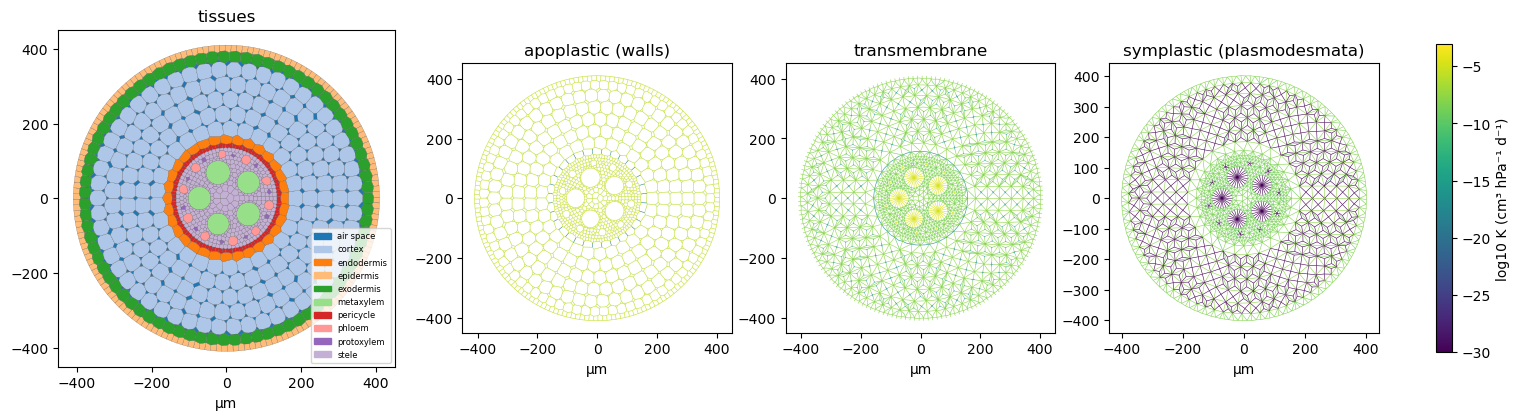

In [5]:
frame = plots.port_frame(mecha, segment)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
plots.tissue_map(axes[0], frame)
lines = plots.conductance_by_path(axes[1:], frame)
fig.colorbar(lines, ax=axes[1:], label="log10 K (cm³ hPa⁻¹ d⁻¹)", shrink=0.8)
plt.show()

## 3. Parametrizing: the scenario

MECHA's parameters (its conductivities, its boundary conditions...) are overridden by the scenario's `parameters`,
in the same dict as GRANAP's anatomies. Four plants: the default, a lower wall conductivity, a lower membrane
conductivity, and another anatomy (a dicot root). Each plant's values are its own.

In [6]:
scenarios = {
    "default": {},
    "kw / 10": {"kw": MechaHydraulics.kw / 10},
    "kmb / 10": {"kmb": MechaHydraulics.kmb / 10},
    "dicot root": {"root_anatomy": {"preset": "for_dicot_root"}},
}
scene = Scene(plants(RootHydraulics, *scenarios.values()))
scene.run()
ds = scene.populations[0].data_structure
pd.DataFrame({"kr (cm hPa⁻¹ d⁻¹)": ds.get("kr"), "uptake (cm³ d⁻¹)": ds.get("standard_uptake")},
             index=list(scenarios))

,kr (cm hPa⁻¹ d⁻¹),uptake (cm³ d⁻¹)
default,0.000110,0.002772
kw / 10,0.000053,0.001342
kmb / 10,0.000107,0.002683
dicot root,0.000132,0.004889


## 4. An input from another model: the barriers

`barrier` is MECHA's maturity code of the apoplastic barriers (1 an endodermal Casparian strip, 3 a suberized
endodermis, 4 an exodermal strip too), an input of role `Development`: a root development model writes it, here a
loop does. Calling the model again recomputes what depends on it.

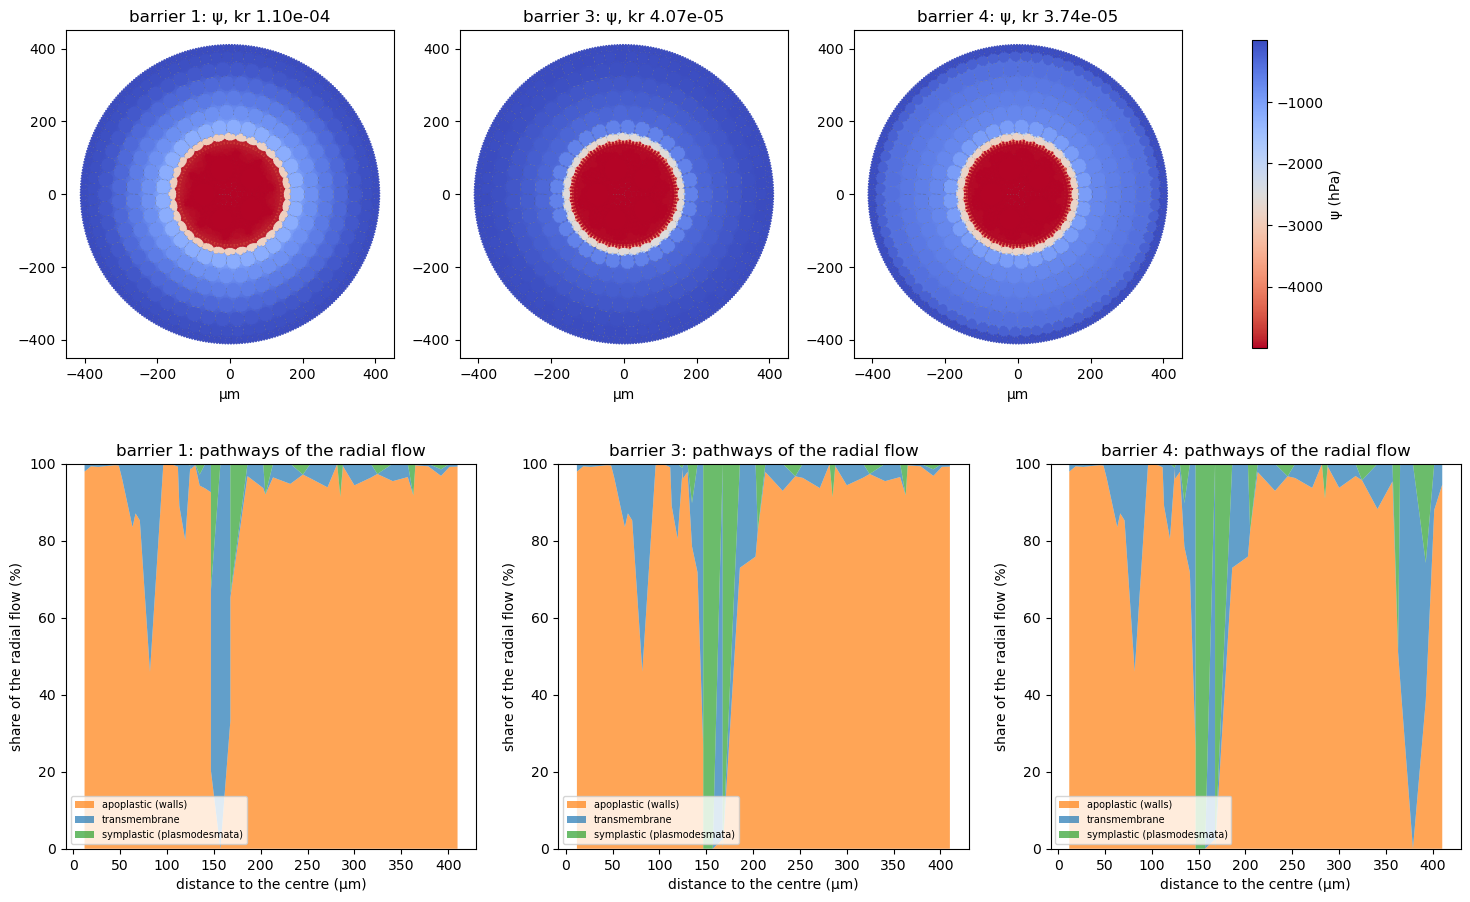

In [7]:
scene = Scene(plants(RootHydraulics, {}))
ds = scene.populations[0].data_structure
mecha = scene.populations[0].instance.hydraulics
frames, kr = {}, {}
for barrier in (1, 3, 4):
    ds.set("barrier", np.full(ds.n_nodes(), float(barrier)))
    scene.run()
    kr[barrier], frames[barrier] = ds.get("kr")[0], plots.port_frame(mecha, segment)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for top, bottom, barrier in zip(axes[0], axes[1], frames):
    points = plots.psi_map(top, frames[barrier], title=f"barrier {barrier}: ψ, kr {kr[barrier]:.2e}")
    plots.pathway_breakdown(bottom, frames[barrier], title=f"barrier {barrier}: pathways of the radial flow")
fig.colorbar(points, ax=axes[0], label="ψ (hPa)", shrink=0.8)
plt.show()

Next: `02_soil_gradient.ipynb`, MECHA's plant problem with a soil drier on one side of the root.